# EDA cho Vi-DFD

## Mục tiêu
Phân tích bộ dữ liệu **VinText** trước khi huấn luyện mô hình nhận dạng chữ tiếng Việt **Vi-DFD**. Notebook tập trung vào **đặc điểm ảnh, hình học vùng chữ, nội dung transcript và dấu tiếng Việt** để xác định khó khăn của bài toán và xây dựng kế hoạch thực nghiệm.

**Quy trình:** 
1. kiểm tra dữ liệu và kết quả cropping  
2. Phân tích ảnh gốc 
3. Phân tích bounding box 
4. Phân tích transcript 
5. Phân tích dấu thanh/dấu cấu tạo 
6. So sánh train/test/unseen_test
7. Kiểm tra trực quan

**Nguồn dữ liệu:** ảnh gốc và `gt_*.txt` trong `dataset/`; các ảnh chữ đã crop và `metadata.csv` trong `processed/vintext_notebook/`.


## Khởi tạo môi trường và đường dẫn

- Import thư viện đọc ảnh (`opencv-python`, `Pillow`), phân tích (`numpy`, `pandas`) và vẽ biểu đồ (`matplotlib`, `seaborn`).
- Tự tìm thư mục gốc `vi-dfd` khi mở notebook từ `notebooks/`.
- Kiểm tra các thư mục nguồn; tự phát hiện kết quả crop từ `processed/vintext_notebook`.
- Xuất bảng CSV vào `results/eda/tables/` và biểu đồ PNG vào `results/eda/figures/`.

Cài dependencies: `python -m pip install -r requirements.txt`.

In [1]:
from pathlib import Path
import csv, math, random, re, unicodedata
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw, ImageFont
import cv2
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 40)
SEED = 42
random.seed(SEED)

ROOT = Path.cwd().resolve()
while not (ROOT / "data").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Không tìm thấy thư mục vi-dfd/data từ thư mục làm việc hiện tại")
    ROOT = ROOT.parent
DATASET = ROOT.parent / "dataset"
CANDIDATES = [ROOT.parent / "processed" / "vintext_notebook", ROOT.parent / "processed" / "vintext"]
PROCESSED = next((p for p in CANDIDATES if (p / "metadata.csv").is_file()), None)
if PROCESSED is None:
    raise FileNotFoundError(f"Không thấy metadata.csv tại: {CANDIDATES}")
OUT = ROOT / "results" / "eda"
FIG = OUT / "figures"
TAB = OUT / "tables"
for p in (FIG, TAB): p.mkdir(parents=True, exist_ok=True)
SPLIT_DIRS = {"train":"train_images", "test":"test_image", "unseen_test":"unseen_test_images"}
SPLIT_ORDER = list(SPLIT_DIRS)
print("Dataset:", DATASET, "\nProcessed:", PROCESSED, "\nOutput:", OUT)
assert (DATASET / "labels").is_dir(), "Missing dataset/labels"
assert (PROCESSED / "metadata.csv").is_file()

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=180, bbox_inches="tight")
    plt.show()

def export(df, name):
    df.to_csv(TAB / name, index=False, encoding="utf-8-sig")

def image_id_from_path(p):
    m = re.search(r"(\d+)$", p.stem)
    return int(m.group(1)) if m else None

def read_cv(path):
    data = np.fromfile(str(path), dtype=np.uint8)
    return cv2.imdecode(data, cv2.IMREAD_COLOR)

Dataset: D:\BTL_DL\dataset 
Processed: D:\BTL_DL\processed\vintext_notebook 
Output: D:\BTL_DL\vi-dfd\results\eda


## 1. Tổng quan bộ dữ liệu (Dataset Overview)

Đọc `metadata.csv` sau cropping và thống kê số lượng ảnh gốc, số lượng word crops hợp lệ theo từng split. Kiểm tra cấu trúc cột, transcript và đường dẫn crop. Bước này giúp xác nhận dữ liệu đầu vào EDA đầy đủ trước khi phân tích sâu.

**Đầu ra:** bảng số ảnh/số crop theo split, biểu đồ so sánh và `01_split_overview.csv`. 

Source images: 2000 | Word crops: 43045


,images,word_crops
split,,
train,1200,25776
test,300,7201
unseen_test,500,10068


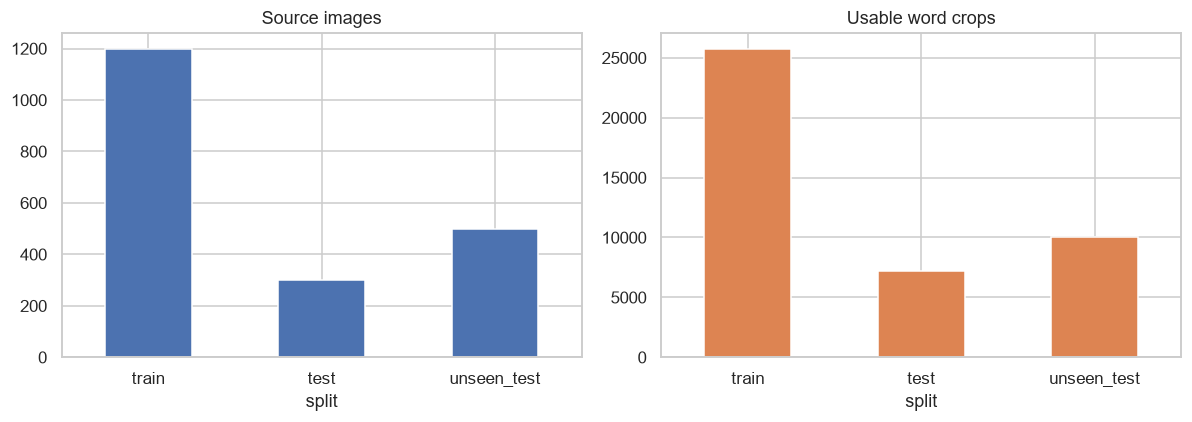

Số transcript không ở dạng NFC: 0
Số đường dẫn crop không tồn tại: 0


In [2]:
meta = pd.read_csv(PROCESSED / "metadata.csv", encoding="utf-8-sig", keep_default_na=False)
required = {"split", "image_id", "transcript", "crop_path", "original_word_height", "original_word_width"}
assert required.issubset(meta.columns), f"Missing metadata fields: {required-set(meta.columns)}"
meta["image_id"] = pd.to_numeric(meta["image_id"], errors="raise").astype(int)
meta["transcript"] = meta["transcript"].astype(str).map(lambda x: unicodedata.normalize("NFC", x))
meta["text_length"] = meta["transcript"].str.len()
for c in ["original_word_height", "original_word_width", "crop_width", "crop_height"]:
    if c in meta: meta[c] = pd.to_numeric(meta[c], errors="coerce")

paths = []
for split, folder in SPLIT_DIRS.items():
    for p in sorted((DATASET / folder).glob("*")):
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            paths.append({"split":split, "image_id":image_id_from_path(p), "path":p})
images = pd.DataFrame(paths)
assert images.image_id.notna().all(), "Cannot parse an image ID"
assert images.image_id.is_unique, "Image IDs must be unique across splits"
print("Source images:", len(images), "| Word crops:", len(meta))
summary = pd.DataFrame({"images": images.groupby("split").size(), "word_crops":meta.groupby("split").size()}).reindex(SPLIT_ORDER).fillna(0).astype(int)
display(summary)
export(summary.reset_index().rename(columns={"index":"split"}), "01_split_overview.csv")
ax = summary.plot(kind="bar", subplots=True, layout=(1,2), figsize=(11,4), legend=False, rot=0, title=["Source images", "Usable word crops"])
savefig("01_split_overview.png")
# Kiểm tra tính nhất quán và các crop thiếu file
print("Số transcript không ở dạng NFC:", sum(not unicodedata.is_normalized("NFC", t) for t in meta.transcript))
missing_crops = sum(not ((PROCESSED / Path(p)).exists() if not Path(p).is_absolute() else Path(p).exists()) for p in meta.crop_path)
print("Số đường dẫn crop không tồn tại:", missing_crops)


## 2. Phân tích đặc điểm ảnh gốc (Image-level)

Đọc từng ảnh nguồn và file `gt_<id>.txt` tương ứng. Tính **chiều rộng, chiều cao, tỷ lệ W/H, độ sáng trung bình (grayscale mean), độ tương phản xấp xỉ (grayscale standard deviation)** và **mật độ vùng chữ** (số box hợp lệ/ảnh). Đồng thời thống kê nhãn bị bỏ qua (`###`) và kiểm tra annotation lỗi.

**Mục đích:** đánh giá độ đa dạng kích thước, điều kiện ánh sáng và độ phức tạp bố cục của ảnh cảnh tự nhiên. Độ lệch chuẩn grayscale chỉ là chỉ số thay thế cho contrast, không phải phép đo độ tương phản cảm nhận tuyệt đối.

**Đầu ra:** `02_image_metrics.csv`, `annotation_issues.csv` (nếu có), biểu đồ phân phối.

In [3]:
def parse_label_file(path):
    rows=[]
    if not path.exists(): return rows, ["missing_label_file"]
    issues=[]
    with path.open(encoding="utf-8-sig") as f:
        for line_no, line in enumerate(f, 1):
            if not line.strip(): continue
            parts = line.rstrip("\r\n").split(",", maxsplit=8)
            if len(parts) != 9:
                issues.append(f"line_{line_no}:field_count")
                continue
            try:
                coords = np.asarray([float(x.strip()) for x in parts[:8]], dtype=np.float32).reshape(4,2)
                if not np.isfinite(coords).all(): raise ValueError("nonfinite")
            except ValueError:
                issues.append(f"line_{line_no}:bad_coords")
                continue
            text = unicodedata.normalize("NFC", parts[8].strip())
            rows.append({"line_number":line_no, "points":coords, "transcript":text,
                         "ignored":text=="###", "empty":text==""})
    return rows, issues

image_records, box_records, label_issues = [], [], []
for r in images.itertuples(index=False):
    im = read_cv(r.path)
    if im is None:
        label_issues.append((r.image_id, "unreadable_image"))
        continue
    h,w = im.shape[:2]
    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    annotations, issues = parse_label_file(DATASET / "labels" / f"gt_{r.image_id}.txt")
    label_issues.extend((r.image_id, issue) for issue in issues)
    valid = sum(not a["ignored"] and not a["empty"] for a in annotations)
    image_records.append({"split":r.split, "image_id":r.image_id, "path":str(r.path),
        "width":w,"height":h,"aspect_ratio":w/h,"brightness":float(gray.mean()),
        "contrast":float(gray.std()),"n_boxes":len(annotations),"n_valid_boxes":valid,
        "n_ignored":sum(a["ignored"] for a in annotations)})
    for a in annotations:
        pts=a["points"]
        top=np.linalg.norm(pts[1]-pts[0]); bottom=np.linalg.norm(pts[2]-pts[3])
        left=np.linalg.norm(pts[3]-pts[0]); right=np.linalg.norm(pts[2]-pts[1])
        bw=max(top,bottom); bh=max(left,right)
        area=abs(cv2.contourArea(pts))
        angle=math.degrees(math.atan2(float(pts[1,1]-pts[0,1]),float(pts[1,0]-pts[0,0])))
        angle=(angle+90)%180-90  # normalized top-edge orientation; not a perspective-distortion metric
        box_records.append({"split":r.split,"image_id":r.image_id,"line_number":a["line_number"],
            "transcript":a["transcript"],"ignored":a["ignored"],"empty":a["empty"],
            "box_width":bw,"box_height":bh,"box_aspect_ratio":bw/max(bh,1e-6),
            "box_area":area,"relative_area":area/(w*h),"angle_deg":angle})
imgdf=pd.DataFrame(image_records)
boxes=pd.DataFrame(box_records)
valid_boxes=boxes.loc[~boxes.ignored & ~boxes.empty & (boxes.box_area>0)].copy()
print("Images decoded:",len(imgdf),"| Annotations:",len(boxes),"| Usable boxes:",len(valid_boxes),"| Issues:",len(label_issues))
export(imgdf.drop(columns="path"),"02_image_metrics.csv")
export(boxes.drop(columns="transcript"),"03_box_metrics.csv")
if label_issues: export(pd.DataFrame(label_issues,columns=["image_id","issue"]),"annotation_issues.csv")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_6464\1910974036.py:52: DeprecationWarning: Bitwise inversion '~' on bool is deprecated and will be removed in Python 3.16. This returns the bitwise inversion of the underlying int object and is usually not what you expect from negating a bool. Use the 'not' operator for boolean negation or ~int(x) if you really want the bitwise inversion of the underlying int.
  valid_boxes=boxes.loc[~boxes.ignored & ~boxes.empty & (boxes.box_area>0)].copy()


Images decoded: 2000 | Annotations: 56084 | Usable boxes: 43100 | Issues: 0


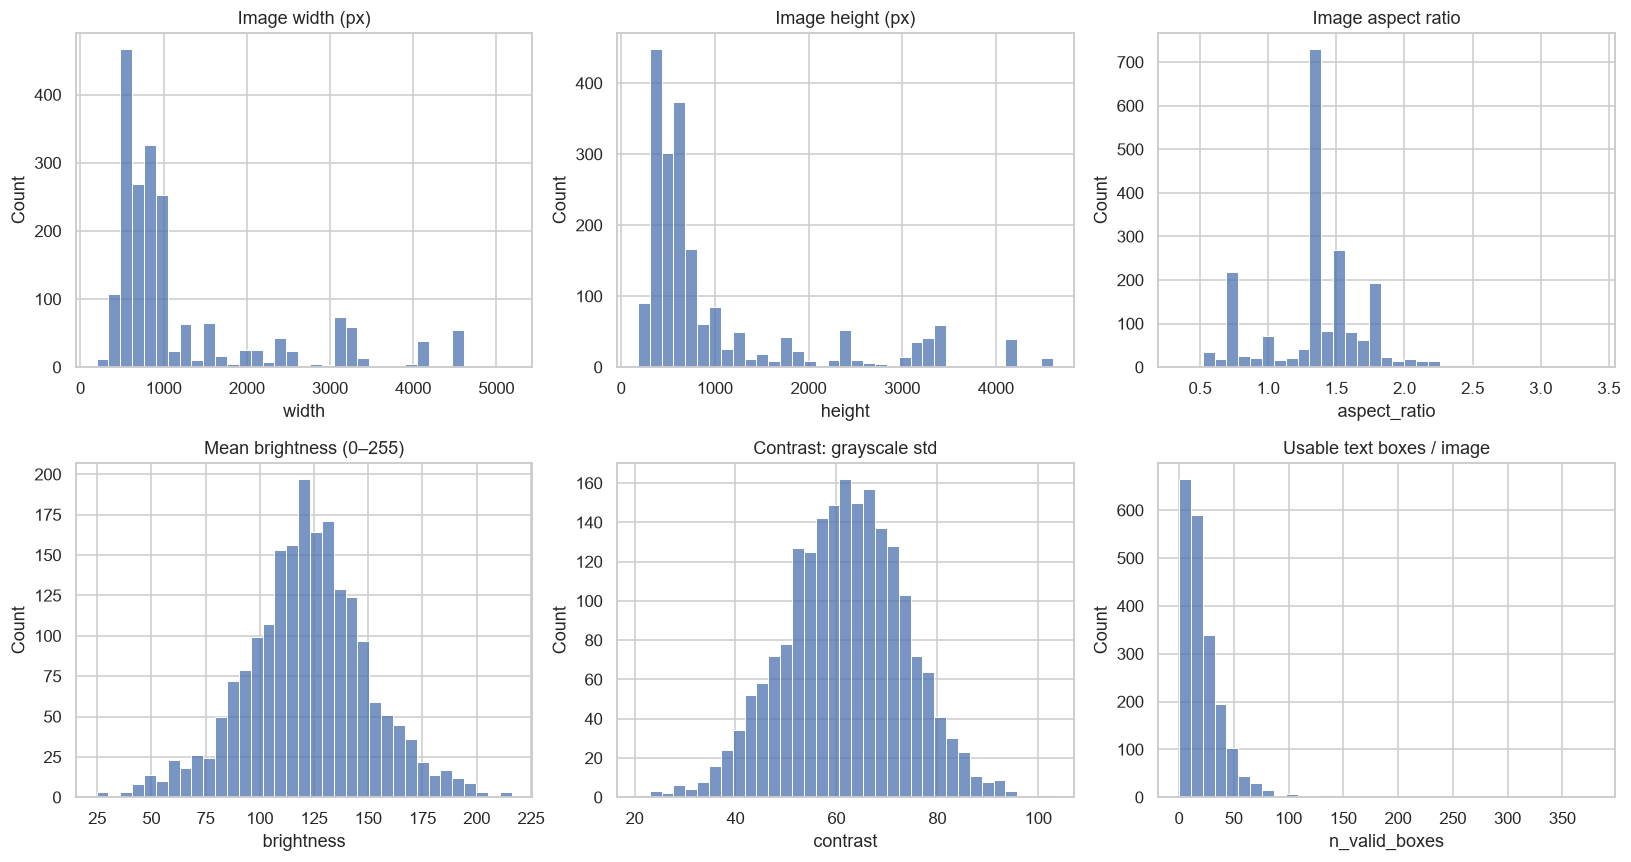

width          height          aspect_ratio       brightness  \
            median     mean median     mean       median  mean     median   
split                                                                       
test         800.0  1237.49  600.0   993.01         1.33  1.37     122.84   
train        800.0  1230.59  600.0  1003.52         1.33  1.37     122.78   
unseen_test  800.0  1267.62  600.0  1066.56         1.33  1.36     119.80   

                    contrast        n_valid_boxes         
               mean   median   mean        median   mean  
split                                                     
test         123.74    61.68  61.74          19.0  24.00  
train        121.45    62.26  61.93          16.0  21.48  
unseen_test  121.46    61.37  61.27          15.0  20.14

In [4]:
fig,axes=plt.subplots(2,3,figsize=(15,8))
for ax,col,title in zip(axes.flat,["width","height","aspect_ratio","brightness","contrast","n_valid_boxes"],
                        ["Image width (px)","Image height (px)","Image aspect ratio","Mean brightness (0–255)","Contrast: grayscale std","Usable text boxes / image"]):
    sns.histplot(imgdf[col],bins=35,ax=ax)
    ax.set_title(title)
savefig("02_image_level_distributions.png")
display(imgdf.groupby("split")[["width","height","aspect_ratio","brightness","contrast","n_valid_boxes"]].agg(["median","mean"]).round(2))

## 3. Phân tích vùng chữ (Bounding-box-level)

Từ bốn điểm của quadrilateral, tính **chiều rộng/chiều cao ước lượng theo cạnh**, tỷ lệ W/H, diện tích tứ giác, diện tích tương đối so với ảnh gốc và góc nghiêng cạnh trên. Chỉ dùng box hợp lệ, không thuộc `###` và không có transcript rỗng để phân tích phân phối.

**Mục đích:** nhận diện vùng chữ nhỏ, dài, nghiêng hoặc chiếm diện tích rất ít — các trường hợp dễ gây lỗi nhận dạng và mất dấu khi crop.

**Lưu ý:** diện tích tứ giác được tính từ tọa độ annotation, không phải diện tích chữ thực tế.

**Đầu ra:** `03_box_metrics.csv` và biểu đồ phân phối hình học.

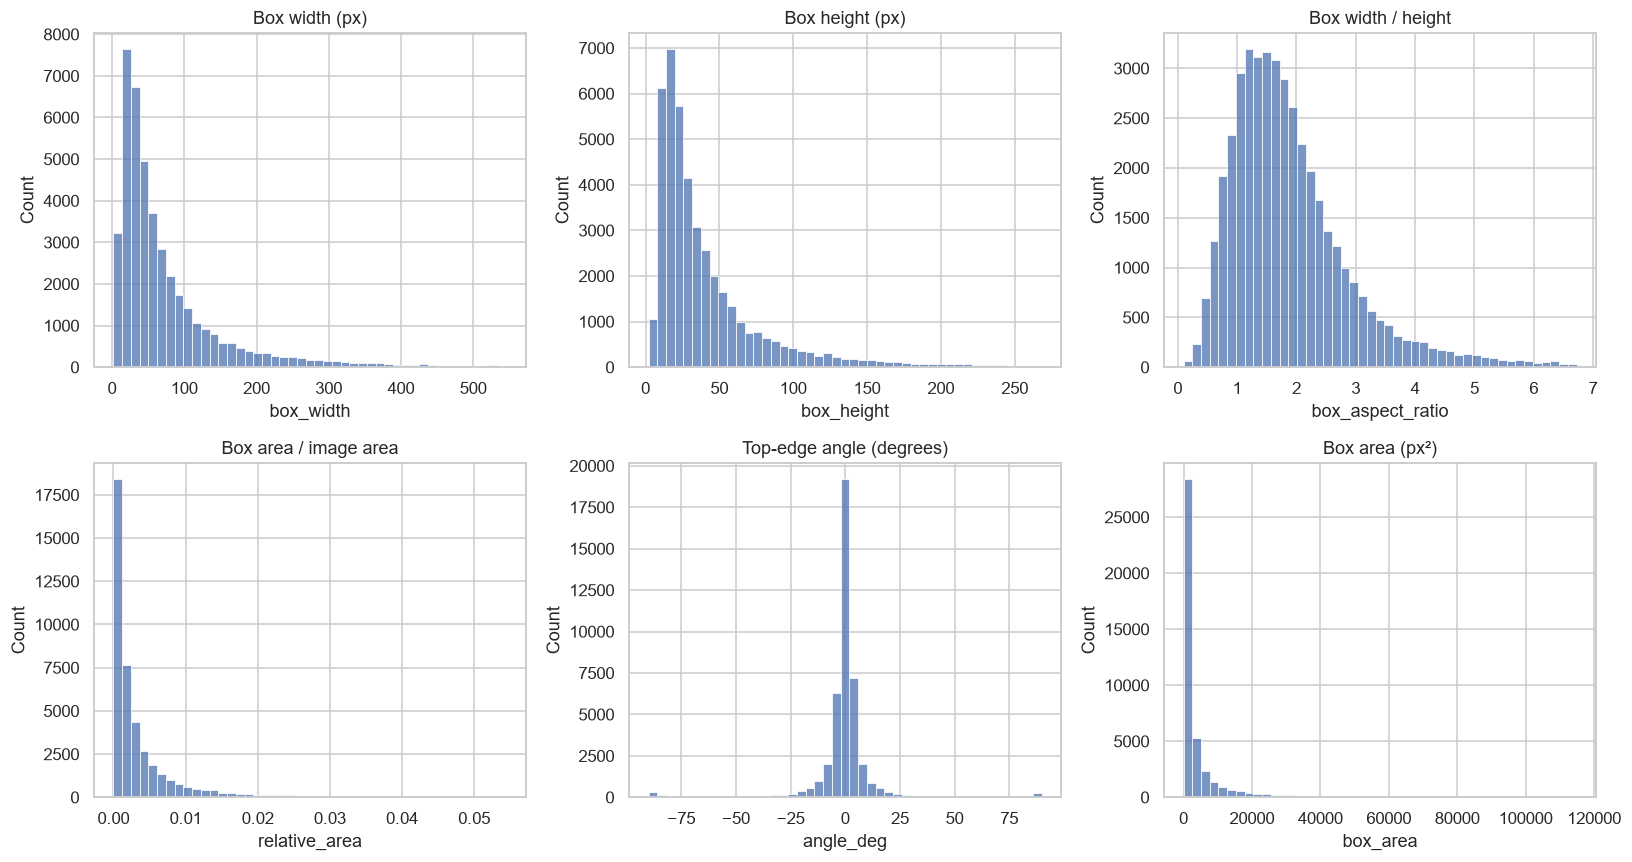

Small original boxes (<16px high): 9555
Strong rotation (|angle| >= 20°): 2968


In [5]:
fig,axes=plt.subplots(2,3,figsize=(15,8))
columns=["box_width","box_height","box_aspect_ratio","relative_area","angle_deg","box_area"]
titles=["Box width (px)","Box height (px)","Box width / height","Box area / image area","Top-edge angle (degrees)","Box area (px²)"]
for ax,col,title in zip(axes.flat,columns,titles):
    vals=valid_boxes[col].replace([np.inf,-np.inf],np.nan).dropna()
    if col in {"box_width","box_height","box_aspect_ratio","box_area","relative_area"}:
        upper=vals.quantile(.99)
        vals=vals[vals<=upper]
    sns.histplot(vals,bins=45,ax=ax)
    ax.set_title(title)
savefig("03_box_level_distributions.png")
print("Small original boxes (<16px high):", int((valid_boxes.box_height<16).sum()))
print("Strong rotation (|angle| >= 20°):", int((valid_boxes.angle_deg.abs()>=20).sum()))

## 4. Phân tích transcript (Text-level)

Transcript từ metadata được chuẩn hóa **Unicode NFC** trước khi thống kê. NFC đưa các cách mã hóa tương đương của chữ tiếng Việt có dấu về dạng thống nhất , **không xóa dấu**. Nhờ đó việc xây dựng vocabulary, mã hóa nhãn và tính CER nhất quán hơn.

Các phân tích gồm: **tần suất ký tự và vocabulary**, **độ dài chuỗi ký tự**, **tần suất token phân tách theo khoảng trắng**, và **kiểu chữ hoa/thường**.

**Lưu ý:** token theo khoảng trắng không phải kết quả tách từ tiếng Việt bằng mô hình ngôn ngữ; một crop có thể chứa nhiều token.

**Đầu ra:** bảng ký tự, token, kiểu chữ và biểu đồ độ dài/tần suất.

Vocabulary size (NFC, case-sensitive): 228


,character,count,codepoint,category
0,N,12081,U+004E,Lu
1,H,9251,U+0048,Lu
2,T,7951,U+0054,Lu
3,C,5963,U+0043,Lu
4,I,5703,U+0049,Lu
5,G,5478,U+0047,Lu
6,A,4170,U+0041,Lu
7,n,3918,U+006E,Ll
8,O,3210,U+004F,Lu
9,0,3093,U+0030,Nd


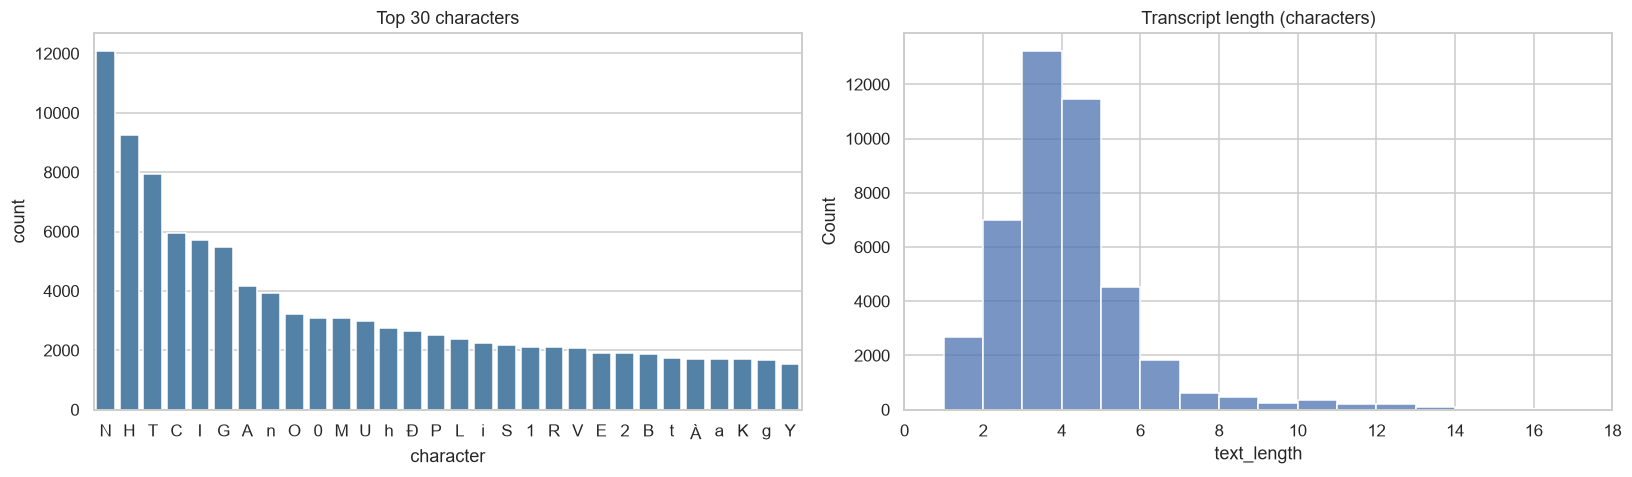

Length percentiles:


,characters
0.50,3.0
0.90,5.0
0.95,7.0
0.99,12.0
1.00,30.0


In [6]:
char_rows=[]
for r in meta.itertuples(index=False):
    for ch in r.transcript:
        char_rows.append((r.split,ch))
chars=pd.DataFrame(char_rows,columns=["split","character"])
char_freq=chars.groupby("character").size().sort_values(ascending=False).rename("count").reset_index()
char_freq["codepoint"] = char_freq.character.map(lambda c: "U+"+format(ord(c),"04X"))
char_freq["category"] = char_freq.character.map(lambda c: unicodedata.category(c))
export(char_freq,"04_character_vocabulary.csv")
print("Vocabulary size (NFC, case-sensitive):",len(char_freq))
display(char_freq.head(30))

fig,axes=plt.subplots(1,2,figsize=(15,4.5))
sns.barplot(data=char_freq.head(30),x="character",y="count",ax=axes[0],color="steelblue")
axes[0].set_title("Top 30 characters")
sns.histplot(meta.text_length,bins=range(0,int(meta.text_length.max())+2),ax=axes[1])
axes[1].set_title("Transcript length (characters)")
axes[1].set_xlim(0,min(int(meta.text_length.quantile(.995))+5,int(meta.text_length.max())+1))
savefig("04_text_character_and_length.png")
print("Length percentiles:")
display(meta.text_length.quantile([.5,.9,.95,.99,1]).rename("characters").to_frame())

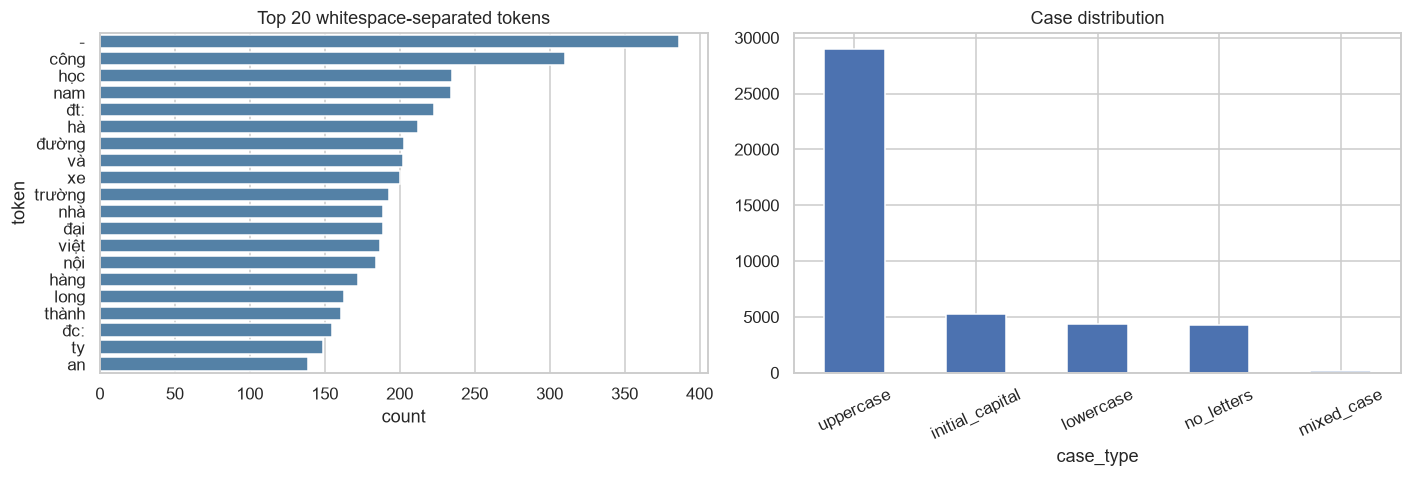

In [7]:
# 'Word frequency' is computed by splitting transcripts on whitespace.
# VinText boxes may contain full phrases, so this is not a Vietnamese word segmenter.
word_counts=Counter(token.casefold() for s in meta.transcript for token in s.split() if token.strip())
word_freq=pd.DataFrame(word_counts.most_common(),columns=["token","count"])
export(word_freq,"05_token_frequency.csv")

def case_type(s):
    letters="".join(c for c in s if c.isalpha())
    if not letters:return "no_letters"
    if letters.isupper():return "uppercase"
    if letters.islower():return "lowercase"
    if letters[0].isupper() and letters[1:].islower():return "initial_capital"
    return "mixed_case"
meta["case_type"]=meta.transcript.map(case_type)
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
sns.barplot(data=word_freq.head(20),x="count",y="token",ax=axes[0],color="steelblue")
axes[0].set_title("Top 20 whitespace-separated tokens")
meta.case_type.value_counts().plot(kind="bar",ax=axes[1],rot=25,title="Case distribution")
savefig("05_tokens_and_case.png")
export(meta.case_type.value_counts().rename_axis("case_type").reset_index(name="count"),"06_case_distribution.csv")

## 5. Phân tích dấu tiếng Việt (Diacritic-focused)

Đây là phần **trọng tâm cho Vi-DFD**. Từng ký tự được phân rã tạm thời sang Unicode NFD để nhận diện các thành phần dấu, **không thay đổi transcript NFC được lưu**:

- **Dấu thanh:** sắc, huyền, hỏi, ngã, nặng (và nhóm không dấu thanh).
- **Dấu cấu tạo nguyên âm:** mũ (`â`, `ê`, `ô`), trăng (`ă`), móc (`ơ`, `ư`).
- **Tổ hợp:** nguyên âm cơ sở + dấu cấu tạo + dấu thanh; tần suất các tổ hợp hiếm.
- **Mật độ dấu:** số ký tự có dấu trong một crop; `đ` được tính là ký tự đặc thù trong chỉ số `marked_chars`, nhưng **không** phải dấu thanh.

**Mục đích:** đánh giá sự mất cân bằng nhãn và xác định nhóm dấu/tổ hợp cần theo dõi khi huấn luyện và báo cáo lỗi. Tần suất được tính **theo ký tự nguyên âm**, không phải theo âm tiết hay từ.

**Đầu ra:** `07_tone_frequency.csv`, `08_vowel_shape_tone_combinations.csv`, heatmap và biểu đồ mật độ dấu.

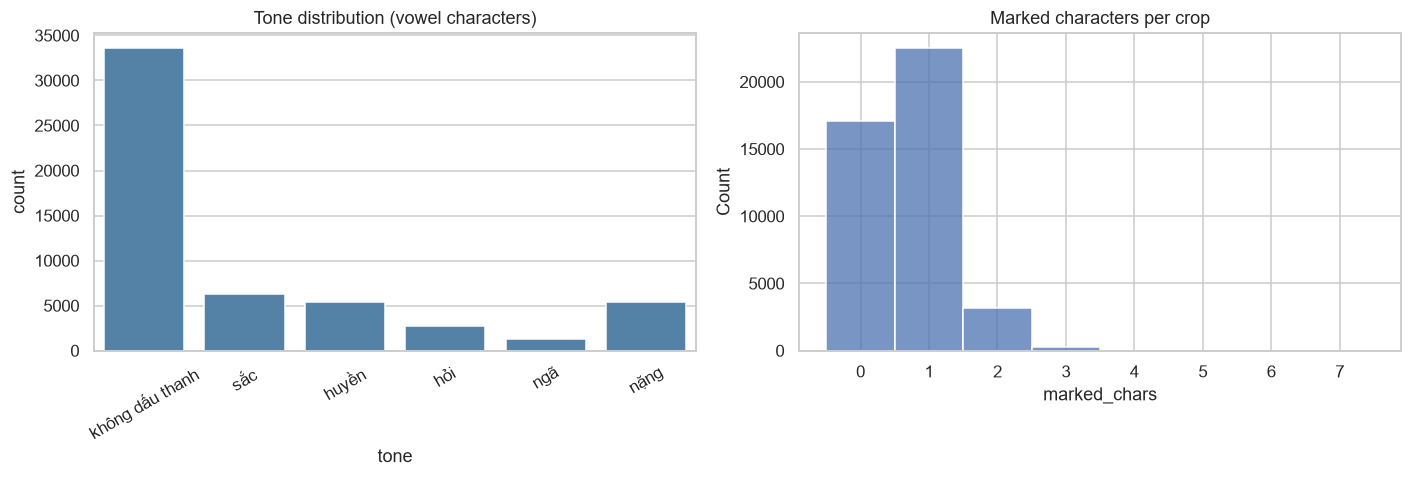

Diacritic-heavy (>=2 marked chars): 3438


In [8]:
TONES={"\u0301":"sắc","\u0300":"huyền","\u0309":"hỏi","\u0303":"ngã","\u0323":"nặng"}
SHAPES={"\u0302":"mũ","\u0306":"trăng","\u031b":"móc"}
VOWELS=set("aeiouy")
def character_features(ch):
    nfd=unicodedata.normalize("NFD",ch.casefold())
    base=nfd[0]
    marks=set(nfd[1:])
    tone=next((name for mark,name in TONES.items() if mark in marks),"không dấu thanh")
    shape="+".join(name for mark,name in SHAPES.items() if mark in marks) or "không dấu cấu tạo"
    marked=any(mark in marks for mark in (*TONES,*SHAPES)) or ch.casefold()=="đ"
    return base,shape,tone,marked

rows=[]
for r in meta.itertuples(index=False):
    for ch in r.transcript:
        base,shape,tone,marked=character_features(ch)
        if base in VOWELS:
            rows.append({"split":r.split,"base":base,"shape":shape,"tone":tone,"combination":f"{base}|{shape}|{tone}"})
vowels=pd.DataFrame(rows)
tone_order=["không dấu thanh","sắc","huyền","hỏi","ngã","nặng"]
tone_freq=vowels.tone.value_counts().reindex(tone_order,fill_value=0).rename_axis("tone").reset_index(name="count")
combo_freq=vowels.combination.value_counts().rename_axis("combination").reset_index(name="count")
export(tone_freq,"07_tone_frequency.csv")
export(combo_freq,"08_vowel_shape_tone_combinations.csv")

meta["marked_chars"] = meta.transcript.map(lambda s:sum(character_features(ch)[3] for ch in s))
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
sns.barplot(data=tone_freq,x="tone",y="count",ax=axes[0],color="steelblue")
axes[0].tick_params(axis="x",rotation=30)
axes[0].set_title("Tone distribution (vowel characters)")
sns.histplot(meta.marked_chars,discrete=True,ax=axes[1])
axes[1].set_title("Marked characters per crop")
savefig("06_tones_and_marked_characters.png")
print("Diacritic-heavy (>=2 marked chars):",int((meta.marked_chars>=2).sum()))

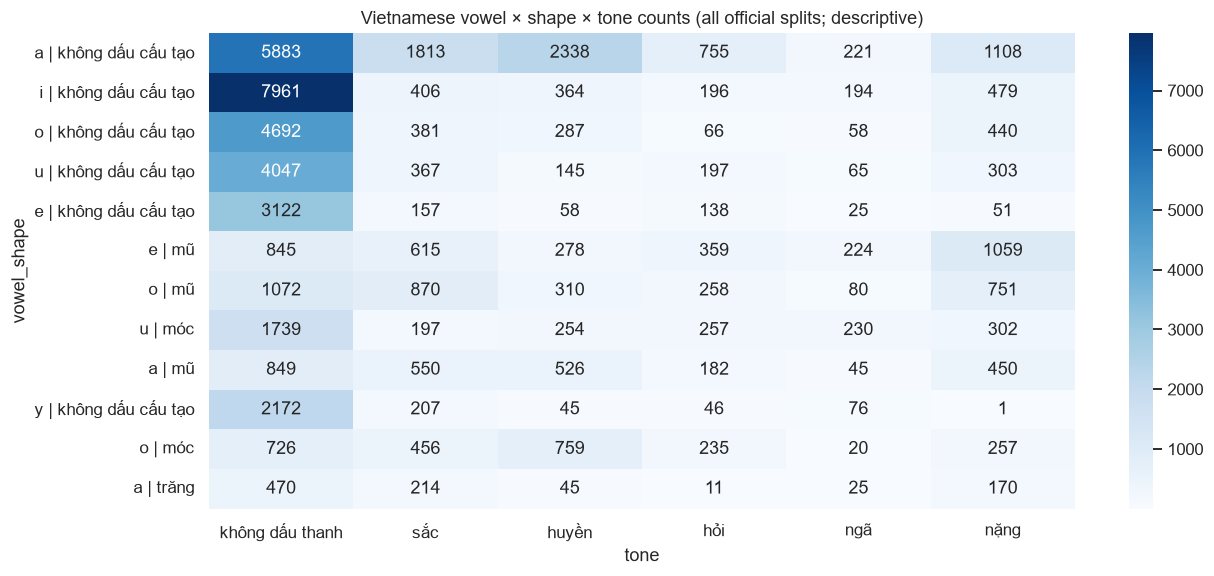

Combinations with <20 occurrences across ALL splits (descriptive only): 2
Do NOT use this all-split count to define rare subsets. Recompute on training split after validation is frozen.


In [9]:
vowels["vowel_shape"] = vowels.base + " | " + vowels["shape"]
heat=pd.crosstab(vowels.vowel_shape,vowels.tone).reindex(columns=tone_order,fill_value=0)
heat=heat.loc[heat.sum(axis=1).sort_values(ascending=False).index]
plt.figure(figsize=(12,max(5,0.45*len(heat))))
sns.heatmap(heat,annot=True,fmt="d",cmap="Blues")
plt.title("Vietnamese vowel × shape × tone counts (all official splits; descriptive)")
savefig("07_diacritic_heatmap.png")
export(heat.reset_index(),"09_diacritic_heatmap.csv")
print("Combinations with <20 occurrences across ALL splits (descriptive only):",int((combo_freq["count"]<20).sum()))
print("Do NOT use this all-split count to define rare subsets. Recompute on training split after validation is frozen.")

## 6. So sánh Train / Test / Unseen Test

So sánh phân phối kích thước ảnh, độ dài transcript, số ký tự có dấu và số lượng crop giữa ba tập chính thức. Kiểm tra **ký tự xuất hiện trong test hoặc unseen_test nhưng không xuất hiện trong train**, dựa trên vocabulary Unicode NFC.

**Mục đích:** xác định khác biệt phân phối và rủi ro out-of-vocabulary (OOV). `unseen_test` được giữ độc lập để đánh giá khả năng tổng quát hóa; **không tự kết luận** rằng tập này chỉ chứa từ/ký tự chưa xuất hiện trong train.

**Đầu ra:** biểu đồ so sánh, bảng thống kê split và danh sách ký tự OOV.

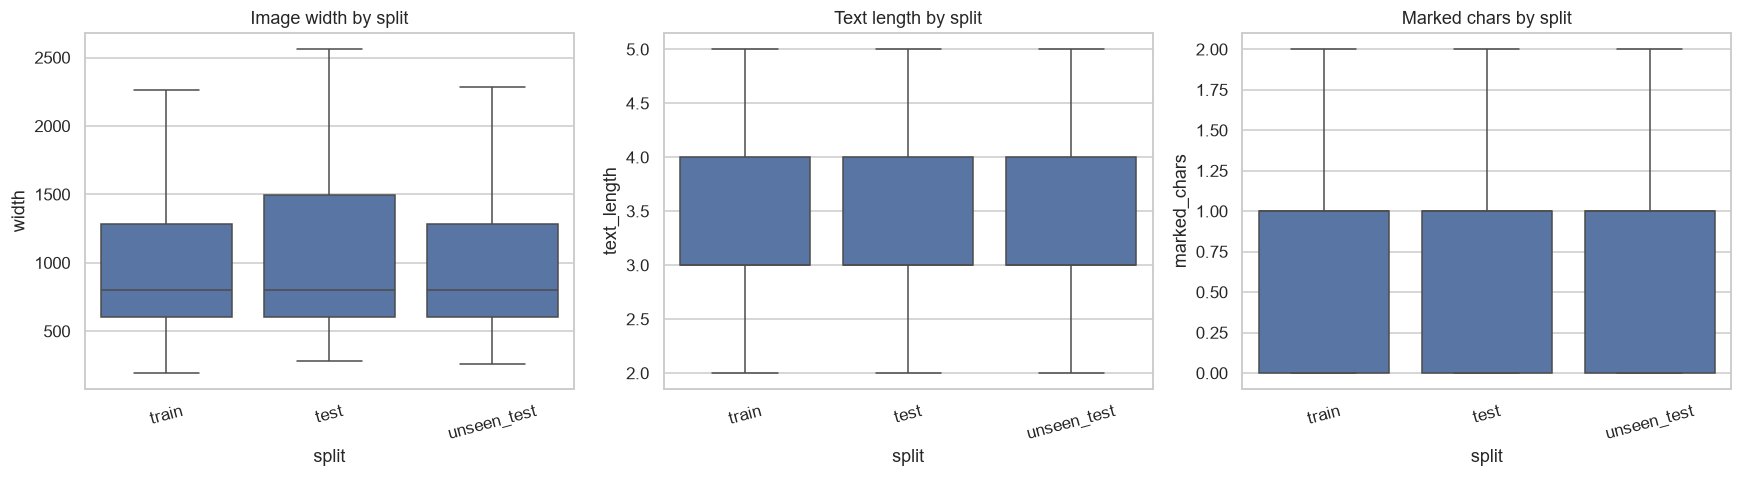

,split,character,codepoint,count
0,test,ẽ,U+1EBD,2
1,unseen_test,ẽ,U+1EBD,2
2,unseen_test,ỵ,U+1EF5,1


Rare combinations (<20) within official train: 5
Final rare-subset definition must be recalculated after train/val split.


In [10]:
fig,axes=plt.subplots(1,3,figsize=(16,4.5))
sns.boxplot(data=imgdf,x="split",y="width",order=SPLIT_ORDER,ax=axes[0],showfliers=False)
axes[0].set_title("Image width by split")
sns.boxplot(data=meta,x="split",y="text_length",order=SPLIT_ORDER,ax=axes[1],showfliers=False)
axes[1].set_title("Text length by split")
sns.boxplot(data=meta,x="split",y="marked_chars",order=SPLIT_ORDER,ax=axes[2],showfliers=False)
axes[2].set_title("Marked chars by split")
for ax in axes:ax.tick_params(axis="x",rotation=15)
savefig("08_split_comparison.png")

train_chars=set("".join(meta.loc[meta.split=="train","transcript"]))
novel=[]
for split in ["test","unseen_test"]:
    freq=Counter("".join(meta.loc[meta.split==split,"transcript"]))
    for ch in sorted(set(freq)-train_chars):
        novel.append({"split":split,"character":ch,"codepoint":f"U+{ord(ch):04X}","count":freq[ch]})
novel_df=pd.DataFrame(novel,columns=["split","character","codepoint","count"])
display(novel_df)
export(novel_df,"10_characters_absent_from_train.csv")

# Frequencies of vowel+shape+tone combinations must be estimated from TRAIN only.
train_combos=vowels.loc[vowels.split=="train","combination"].value_counts()
rare_train=train_combos[train_combos<20]
print("Rare combinations (<20) within official train:",len(rare_train))
print("Final rare-subset definition must be recalculated after train/val split.")
export(train_combos.rename_axis("combination").reset_index(name="train_count"),"11_train_combination_counts_pre_val.csv")

## 7. Kiểm tra trực quan (Visual Inspection)

Hiển thị ảnh gốc cùng quadrilateral và transcript để kiểm tra vị trí annotation. Sau đó hiển thị các ảnh crop ở những trường hợp đáng chú ý: **vùng chữ rất thấp, transcript dài, chứa ký hiệu/dấu câu**.

**Mục đích:** phát hiện nhãn sai, chữ bị cắt mất nét/dấu, crop mờ, méo hoặc lề chưa phù hợp. Đây là bước kiểm tra định tính, không thay thế phép đo định lượng.

**Lưu ý:** việc hiển thị transcript trên ảnh cần font hỗ trợ Unicode tiếng Việt; ảnh crop được đọc từ thư mục `PROCESSED` đã chọn ở bước 0.

unseen_test / im1861 — 40 valid boxes


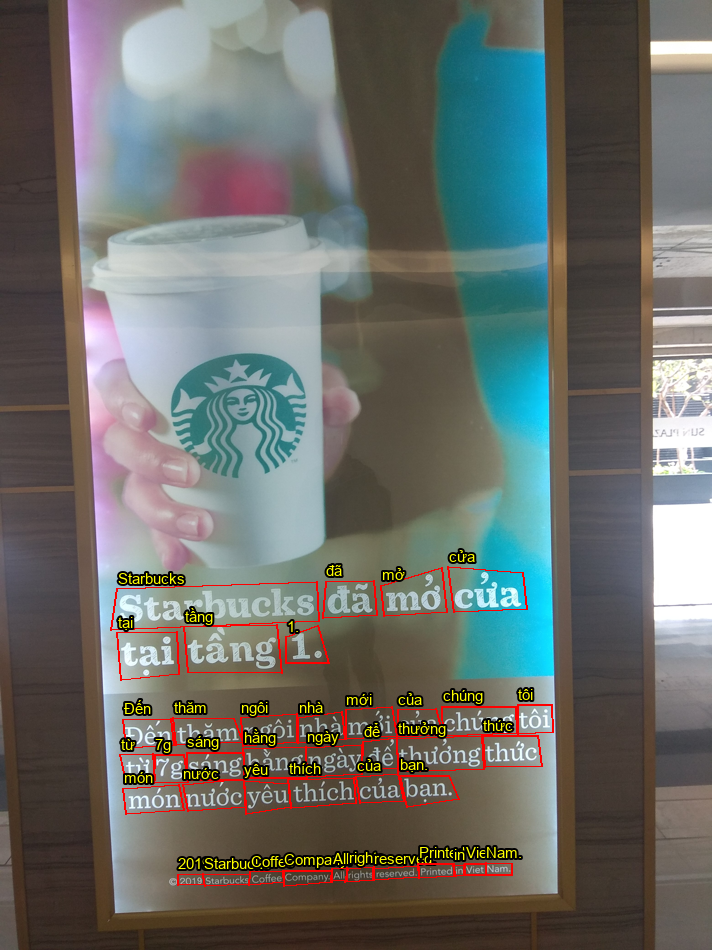

train / im0354 — 34 valid boxes


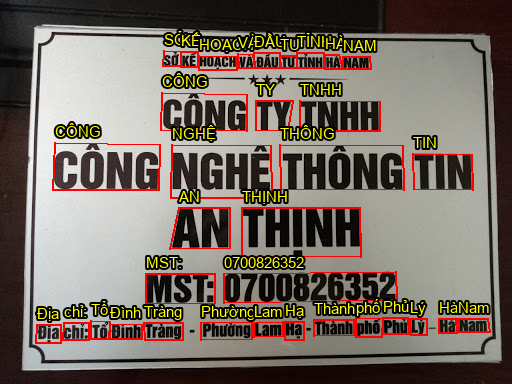

test / im1334 — 7 valid boxes


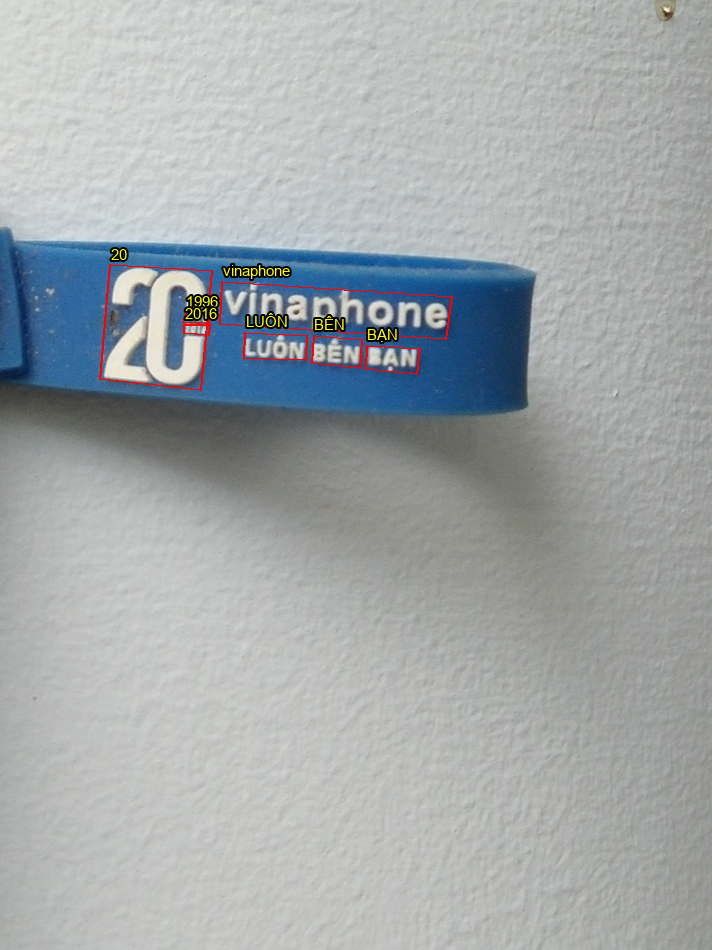

train / im0906 — 24 valid boxes


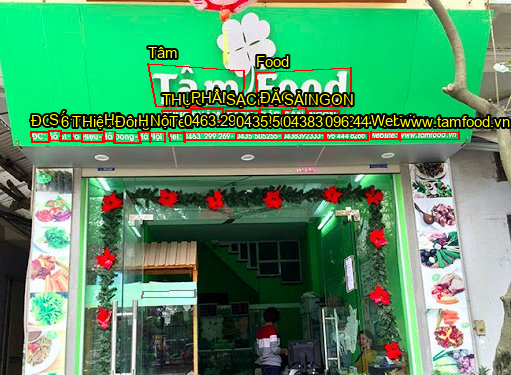

In [11]:
FONT_CANDIDATES=[Path("C:/Windows/Fonts/arial.ttf"),Path("C:/Windows/Fonts/segoeui.ttf"),Path("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf")]
def font(size=16):
    for f in FONT_CANDIDATES:
        if f.exists():return ImageFont.truetype(str(f),size)
    return ImageFont.load_default()

def show_annotated(image_row,max_side=950):
    p=Path(image_row["path"])
    im=Image.open(p).convert("RGB")
    original_w,original_h=im.size
    scale=min(1,max_side/max(im.size))
    if scale<1:im=im.resize((round(original_w*scale),round(original_h*scale)))
    draw=ImageDraw.Draw(im)
    annotations,_=parse_label_file(DATASET/"labels"/f"gt_{int(image_row['image_id'])}.txt")
    for a in annotations:
        pts=[tuple(map(float,xy*scale)) for xy in a["points"]]
        color="gray" if a["ignored"] else "red"
        draw.line(pts+[pts[0]],fill=color,width=2)
        if not a["ignored"] and a["transcript"]:
            x,y=pts[0]
            draw.text((max(0,x),max(0,y-19)),a["transcript"],fill="yellow",stroke_width=2,stroke_fill="black",font=font(15))
    display(im)

samples=imgdf.sample(n=min(4,len(imgdf)),random_state=SEED)
for _,r in samples.iterrows():
    print(f"{r['split']} / im{int(r['image_id']):04d} — {int(r['n_valid_boxes'])} valid boxes")
    show_annotated(r)

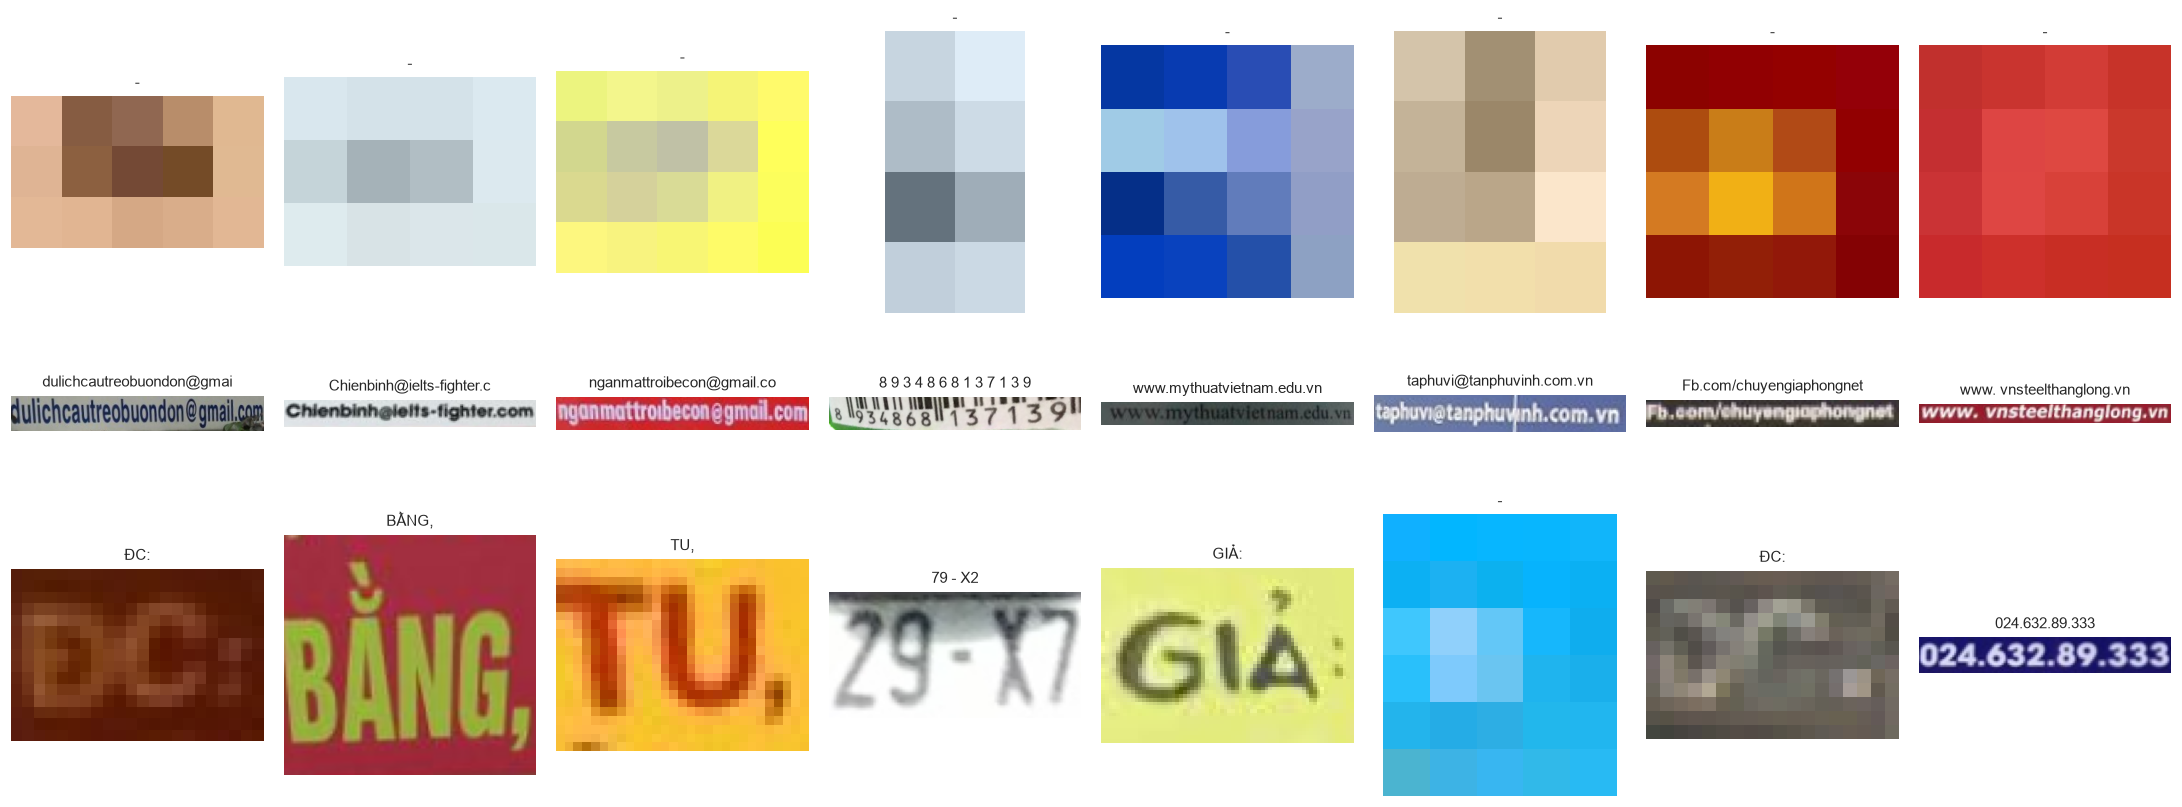

In [12]:
# Crop examples: small original word height, long transcript, and rare non-alphanumeric symbols.
# Crop paths are expected to be relative to PROCESSED as written by crop_vintext.py.
def resolve_crop_path(s):
    p=Path(str(s))
    return p if p.is_absolute() else PROCESSED/p

punct=meta[meta.transcript.map(lambda s:any(not(c.isalnum() or c.isspace()) for c in s))]
choices={
    "small_height":meta.nsmallest(8,"original_word_height"),
    "long_text":meta.nlargest(8,"text_length"),
    "punctuation_or_symbols":punct.sample(n=min(8,len(punct)),random_state=SEED) if len(punct) else punct,
}
fig,axes=plt.subplots(3,8,figsize=(20,7.5))
for i,(category,rows) in enumerate(choices.items()):
    for j,ax in enumerate(axes[i]):
        ax.axis("off")
        if j>=len(rows):continue
        r=rows.iloc[j]
        p=resolve_crop_path(r.crop_path)
        if p.exists():
            with Image.open(p) as im:ax.imshow(im.convert("RGB"))
        else:ax.text(.5,.5,"MISSING",ha="center")
        ax.set_title(str(r.transcript)[:25],fontsize=10)
    axes[i,0].set_ylabel(category,fontsize=10)
savefig("09_crop_edge_cases.png")

## 8. Tổng hợp phát hiện và hàm ý cho Vi-DFD

**Điền kết quả thực tế sau khi chạy toàn bộ notebook**, không suy đoán trước:

1. **Ảnh gốc:** dải kích thước, độ sáng/contrast và số box mỗi ảnh; điều kiện nào chiếm ưu thế?
2. **Vùng chữ:** tỷ lệ box rất nhỏ, rất dài hoặc nghiêng; nguy cơ crop mất dấu ở đâu?
3. **Transcript:** kích thước vocabulary, độ dài phổ biến, ký tự hiếm và phân bố chữ hoa/thường.
4. **Dấu tiếng Việt:** dấu thanh/dấu cấu tạo nào ít mẫu? Tổ hợp nào có nguy cơ học kém?
5. **Khác biệt split:** test/unseen_test có ký tự OOV hoặc phân phối khác train không?
6. **Kiểm tra trực quan:** các ví dụ lỗi annotation/crop đáng lưu ý và cách xử lý.

**Sản phẩm:** bảng `.csv` và biểu đồ `.png` dưới `results/eda/`, phục vụ báo cáo phân tích dữ liệu và thiết kế thí nghiệm Vi-DFD.